<a href="https://colab.research.google.com/github/diegotellez401a-ux/robot-2gdl-euler-lagrange/blob/main/robot_2gdl_simulacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

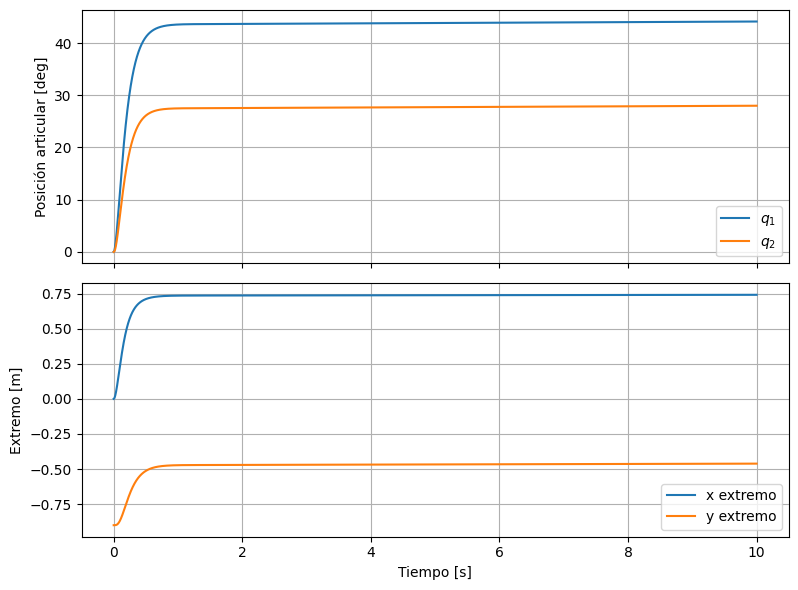

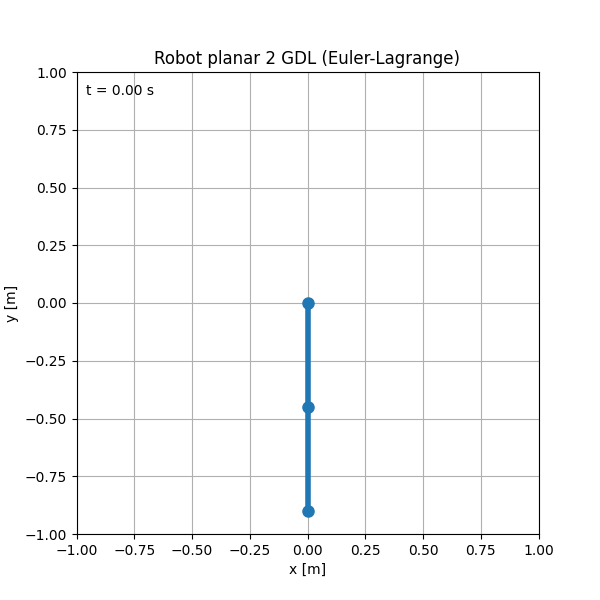

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import Image

# ---------------- PARÁMETROS (verifica con tu libro) ----------------
m1, m2 = 23.902, 3.880
l1, l2 = 0.45, 0.45
lc1, lc2 = 0.091, 0.048
I1, I2 = 1.266, 0.093
b1, b2 = 2.288, 0.175
fc1, fc2 = 7.17, 1.734
fe1, fe2 = 8.45, 2.35
g = 9.81
b = np.array([b1, b2]); fc = np.array([fc1, fc2]); fe = np.array([fe1, fe2])

# ---------------- MATRICES DEL MODELO ----------------
def M(q):
    c2 = np.cos(q[1])
    M11 = m1*lc1**2 + m2*l1**2 + m2*lc2**2 + 2*m2*l1*lc2*c2 + I1 + I2
    M12 = m2*lc2**2 + m2*l1*lc2*c2 + I2
    M22 = m2*lc2**2 + I2
    return np.array([[M11, M12], [M12, M22]])

def C(q, qd):
    h = m2*l1*lc2*np.sin(q[1])
    return np.array([[-2*h*qd[1], -h*qd[1]],
                     [ h*qd[0],    0.0   ]])

def G(q):
    s1, s12 = np.sin(q[0]), np.sin(q[0] + q[1])
    return g*np.array([lc1*m1*s1 + m2*l1*s1 + m2*lc2*s12,
                       lc2*m2*s12])

def sat(x, mu):
    return np.clip(x, -mu, mu)

def friccion(q, qd, tau_v, eps=1e-3):
    f = b*qd + fc*np.sign(qd)
    reposo = np.abs(qd) < eps
    neto = tau_v - C(q, qd) @ qd - G(q)
    f[reposo] = sat(neto, fe)[reposo]
    return f

# ---------------- PARES DE LOS MOTORES (PD + gravedad) ----------------
q_des = np.array([np.pi/4, np.pi/6])
Kp = np.array([300.0, 40.0]); Kd = np.array([60.0, 8.0])

def tau(t, q, qd):
    return Kp*(q_des - q) - Kd*qd + G(q)

# ---------------- SIMULACIÓN 10 s (RK4) ----------------
def f_estado(t, x):
    q, qd = x[:2], x[2:]
    tv = tau(t, q, qd)
    qdd = np.linalg.solve(M(q), tv - C(q, qd) @ qd - G(q) - friccion(q, qd, tv))
    return np.concatenate([qd, qdd])

T, dt = 10.0, 1e-3
t = np.arange(0, T + dt, dt)
X = np.zeros((len(t), 4))
for k in range(len(t) - 1):
    x, tk = X[k], t[k]
    k1 = f_estado(tk, x)
    k2 = f_estado(tk + dt/2, x + dt/2*k1)
    k3 = f_estado(tk + dt/2, x + dt/2*k2)
    k4 = f_estado(tk + dt, x + dt*k3)
    X[k+1] = x + dt/6*(k1 + 2*k2 + 2*k3 + k4)

q1, q2 = X[:, 0], X[:, 1]
x1, y1 = l1*np.sin(q1), -l1*np.cos(q1)
x2, y2 = x1 + l2*np.sin(q1 + q2), y1 - l2*np.cos(q1 + q2)

# ---------------- GRÁFICAS ----------------
fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax[0].plot(t, np.degrees(q1), label="$q_1$"); ax[0].plot(t, np.degrees(q2), label="$q_2$")
ax[0].set_ylabel("Posición articular [deg]"); ax[0].legend(); ax[0].grid()
ax[1].plot(t, x2, label="x extremo"); ax[1].plot(t, y2, label="y extremo")
ax[1].set_ylabel("Extremo [m]"); ax[1].set_xlabel("Tiempo [s]"); ax[1].legend(); ax[1].grid()
plt.tight_layout(); plt.show()

# ---------------- ANIMACIÓN (GIF) ----------------
fig2, ax2 = plt.subplots(figsize=(6, 6))
R = l1 + l2 + 0.1
ax2.set_xlim(-R, R); ax2.set_ylim(-R, R); ax2.set_aspect("equal"); ax2.grid()
ax2.set_xlabel("x [m]"); ax2.set_ylabel("y [m]"); ax2.set_title("Robot planar 2 GDL (Euler-Lagrange)")
link, = ax2.plot([], [], "o-", lw=4, color="tab:blue", markersize=8)
traza, = ax2.plot([], [], "r--", lw=1)
txt = ax2.text(0.02, 0.95, "", transform=ax2.transAxes)

def update(i):
    link.set_data([0, x1[i], x2[i]], [0, y1[i], y2[i]])
    traza.set_data(x2[:i+1], y2[:i+1])
    txt.set_text(f"t = {t[i]:.2f} s")
    return link, traza, txt

anim = FuncAnimation(fig2, update, frames=range(0, len(t), 50), interval=50, blit=True)
anim.save("robot_2gdl.gif", writer="pillow", fps=20)
plt.close(fig2)
Image("robot_2gdl.gif")